Confusion matrix is 

[[175  37]
 [ 13 344]]
classification_report is 

              precision    recall  f1-score   support

           0       0.93      0.83      0.88       212
           1       0.90      0.96      0.93       357

    accuracy                           0.91       569
   macro avg       0.92      0.89      0.90       569
weighted avg       0.91      0.91      0.91       569

[[ 9.19283683  1.94858307]
 [ 2.3878018  -3.76817174]
 [ 5.73389628 -1.0751738 ]
 ...
 [ 1.25617928 -1.90229671]
 [10.37479406  1.67201011]
 [-5.4752433  -0.67063679]]


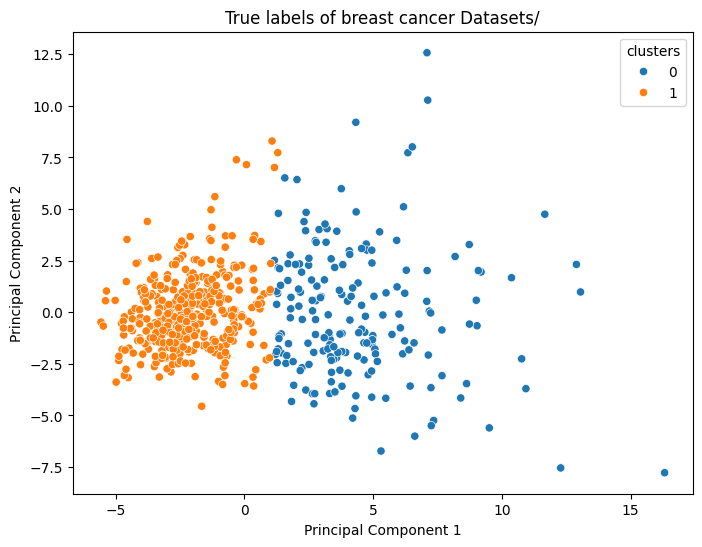

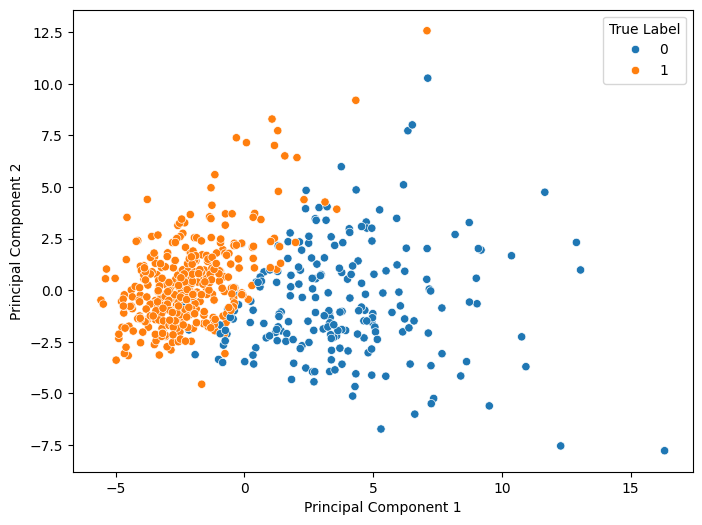

In [26]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.decomposition import PCA
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix,classification_report
from sklearn.cluster import KMeans
from pprint import pprint
import seaborn as sns

data = load_breast_cancer() 
X = data.data
y = data.target


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=2,random_state=42)
y_pred = kmeans.fit_predict(X_scaled)

print("Confusion matrix is \n")
print(confusion_matrix(y,y_pred))

print("classification_report is \n")
print(classification_report(y,y_pred))

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(X_pca)

df = pd.DataFrame(X_pca,columns=['PC1','PC2'])
df['clusters'] = y_pred
df['True Label'] = y

# Plotting based on clusters
plt.figure(figsize=(8, 6)) 
sns.scatterplot(data=df,x='PC1',y='PC2',hue='clusters')
plt.title("True labels of breast cancer Datasets/")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# Plotting based on True Labels
plt.figure(figsize=(8,6))
sns.scatterplot(data=df,x='PC1',y='PC2',hue='True Label')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()